# Clean vs. Dirty Place Classification
## CNN vs. Transformer vs. Mamba backbones (PyTorch, Google Colab)

This notebook is a complete, re-runnable pipeline for the assignment: it audits and splits your phone-photo dataset, fine-tunes pretrained **CNN**, **Transformer** and **Mamba-based** backbones for binary classification (Clean / Dirty), evaluates them with one common protocol, compares their cost and speed, and visualises correct and incorrect predictions.

**Runtime:** Colab with a GPU (T4 is enough): `Runtime -> Change runtime type -> GPU`.

### How the assignment tasks map to this notebook

| Assignment task | Section |
|---|---|
| 1. Dataset collection | You did this; Section 1 documents it (counts, formats, sizes, orientation, capture time) |
| 2. Dataset preparation (labels, train/val/test) | Sections 1.3 (label check), 2 (grouped, stratified split, leakage checks, export of the prepared dataset) |
| 3. Model implementation and fine-tuning | Sections 3 (models), 4 (training) |
| 4. Performance evaluation | Section 5 (accuracy, precision, recall, F1, confusion matrices, ROC, calibration, confidence intervals, significance tests) |
| 5. Comparative analysis (performance, computation, speed) | Section 6 (parameters, model size, FLOPs, latency, throughput, memory, training time) |
| 6. Result visualisation and error analysis | Section 7 (correct / incorrect examples, saliency maps, factors affecting performance) |
| Deliverables | Section 8 (trained models, tables, README and requirements for the GitHub repository) |

### Models compared

| Family | Backbone (pretrained on ImageNet) | Why |
|---|---|---|
| CNN | **ResNet-50** (`resnet50.a1_in1k`), ConvNeXt-Tiny (`convnext_tiny.fb_in1k`) | The classic CNN baseline and a modern CNN with transformer-style design |
| Transformer | **ViT-Small/16** (`vit_small_patch16_224.augreg_in21k_ft_in1k`), Swin-Tiny (`swin_tiny_patch4_window7_224.ms_in1k`) | Global self-attention (ViT) and a hierarchical windowed transformer (Swin) |
| Mamba | **MambaVision-Tiny** (`nvidia/MambaVision-T-1K`) | A hierarchical vision backbone whose middle stages use Mamba selective state-space mixers, with self-attention blocks at the end of each stage |

The bold models are the three required families; the other two are optional extras that make the family comparison less dependent on one architecture. All use the same data, resolution (224 x 224), optimiser recipe, early-stopping rule and evaluation code.

### Design decisions you should know about
* **Positive class = Dirty** (label 1). Precision and recall refer to detecting dirty places; macro-averaged values are reported too.
* **No leakage between splits.** Photos taken minutes apart show the same place. If the images carry EXIF timestamps, they are grouped into capture sessions and **whole sessions go to one split** (stratified by class). Otherwise a stratified random split is used, and the notebook says so.
* **Several seeds.** With a test set of about 45 images, one image is worth more than 2 accuracy points, so every model is trained with 3 seeds (same split) and results are reported as mean and standard deviation.
* **The Mamba backbone and its speed.** The official MambaVision code needs a compiled CUDA extension (`mamba-ssm`) that is often impossible to install on a new Colab image. The notebook therefore loads the **official model code and the official pretrained weights** and replaces only the selective-scan function by a **pure-PyTorch implementation** (mathematically the same recurrence, but slower). Accuracy results are unaffected; **latency and throughput of the Mamba model are therefore pessimistic**, and the notebook labels them as such. If the real kernels are installed they are used automatically.
* **Fallback.** If MambaVision cannot be loaded at all, the notebook falls back to MambaOut-Tiny (timm), which belongs to the "Mamba family" by name but **contains no state-space layer**; it is clearly labelled in all tables so you can state this in the report.

> **What has not been run for you.** I wrote this without access to your GPU or your images, so I could only check that the code parses and that the data-split and metric functions work on synthetic data. The first run may need small fixes. Every risky step is wrapped so that a failure is reported and the rest still runs.

## 0. Setup

In [37]:
!pip -q install timm einops safetensors huggingface_hub scikit-learn scipy tqdm

In [38]:
import os, sys, io, json, math, time, random, shutil, copy, gc, re, types, importlib, hashlib, warnings
from pathlib import Path
from collections import Counter, defaultdict
from time import perf_counter

import numpy as np
import pandas as pd
import cv2
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision, torchvision.transforms as T
import timm
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, confusion_matrix, roc_auc_score, roc_curve,
                             precision_recall_curve, average_precision_score, balanced_accuracy_score, brier_score_loss)
from scipy import stats

warnings.filterwarnings('ignore')
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
assert DEVICE == 'cuda', 'Please switch the Colab runtime to a GPU.'
GPU_NAME = torch.cuda.get_device_name(0)
print('torch', torch.__version__, '| torchvision', torchvision.__version__, '| timm', timm.__version__)
print('GPU:', GPU_NAME, '| memory (GB):', round(torch.cuda.get_device_properties(0).total_memory / 2**30, 1))

torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | timm 1.0.30
GPU: Tesla T4 | memory (GB): 14.6


In [39]:
# -----------------------------------------------------------------------------
# Paths (match the folders you described) and global settings
# -----------------------------------------------------------------------------
QUICK_TEST = False    # True: 2 epochs, one seed. Only to check that every cell runs (results go to a separate folder).
from google.colab import drive
drive.mount('/content/drive')

ROOT      = Path('/content/drive/MyDrive/Clean_Dirty')
CLEAN_DIR = ROOT / 'Clean_Image'
DIRTY_DIR = ROOT / 'Dirty_image'
OUT       = ROOT / ('Experiments_quicktest' if QUICK_TEST else 'Experiments')
DIRS = {k: OUT / k for k in ('models', 'figures', 'tables', 'predictions', 'histories')}
for d in DIRS.values(): d.mkdir(parents=True, exist_ok=True)

SEED_SPLIT       = 42                 # seed of the data split (fixed for all models)
SEEDS            = [42] if QUICK_TEST else [42, 43, 44]   # training seeds
IMG_SIZE         = 224
CACHE_SHORT_SIDE = 288                # images are cached in RAM with the short side limited to this value
TEST_FRAC = VAL_FRAC = 0.15
SESSION_GAP_MIN  = 10                 # photos more than this many minutes apart start a new capture session
CLASS_NAMES      = ['Clean', 'Dirty']  # label 0 = Clean, label 1 = Dirty (positive class)
SWAP_FOLDER_LABELS = None             # None = decide automatically (see Section 1.3); True / False = your explicit decision
EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
def savefig(name): plt.savefig(DIRS['figures'] / f'{name}.png', dpi=150, bbox_inches='tight')
seed_everything(SEED_SPLIT)
for p in (CLEAN_DIR, DIRTY_DIR): print('OK ' if p.exists() else 'MISSING', p)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
OK  /content/drive/MyDrive/Clean_Dirty/Clean_Image
OK  /content/drive/MyDrive/Clean_Dirty/Dirty_image


## 1. Dataset audit (Tasks 1 and 2)

### 1.1 What is in the two folders?

The notebook lists both folders, checks that every file opens, applies the **EXIF orientation** (phone photos are often stored rotated and carry only a flag), and records size, orientation and capture time.

In [40]:
def list_files(d): return sorted(p for p in Path(d).iterdir() if p.is_file())

def read_image(path):
    im = Image.open(path); rotated = False
    ex = im.getexif()
    if ex.get(274, 1) not in (None, 1): rotated = True
    im = ImageOps.exif_transpose(im).convert('RGB')
    return im, rotated

def exif_time(path):
    try:
        ex = Image.open(path).getexif(); v = ex.get_ifd(0x8769).get(36867) or ex.get(306)
        return pd.to_datetime(v, format='%Y:%m:%d %H:%M:%S') if v else pd.NaT
    except Exception: return pd.NaT

rows, corrupt = [], []
for folder, fold_label in ((CLEAN_DIR, 0), (DIRTY_DIR, 1)):
    fs = list_files(folder)
    print(f'{folder.name}: {len(fs)} files | types {dict(Counter(p.suffix.lower() for p in fs))} | first file: {fs[0].name if fs else None}')
    for p in tqdm(fs, desc=folder.name, leave=False):
        if p.suffix.lower() not in EXT: corrupt.append((p.name, 'unsupported extension')); continue
        try:
            im, rot = read_image(p)
            rows.append(dict(file_id=f'{folder.name}/{p.name}', name=p.name, folder=folder.name, folder_label=fold_label, path=str(p),
                             W=im.width, H=im.height, exif_rotated=rot, exif_time=exif_time(p), size_kb=p.stat().st_size / 1024))
        except Exception as e: corrupt.append((p.name, str(e)[:80]))
DF = pd.DataFrame(rows)
print('\nreadable images:', len(DF), '| unreadable:', len(corrupt), corrupt[:5])
print('images stored rotated (EXIF flag):', int(DF.exif_rotated.sum()))
print('images with an EXIF capture time:', int(DF.exif_time.notna().sum()), 'of', len(DF))
display(DF.groupby('folder').agg(images=('name', 'count'), median_W=('W', 'median'), median_H=('H', 'median'), median_kb=('size_kb', 'median'),
                                  portrait=('H', lambda s: int((s > DF.loc[s.index, 'W']).sum()))))
print('most common sizes (W x H):'); print(pd.Series([f'{w}x{h}' for w, h in zip(DF.W, DF.H)]).value_counts().head(6).to_string())

Clean_Image: 155 files | types {'.jpg': 155} | first file: clean_image_001.jpg


Clean_Image:   0%|          | 0/155 [00:00<?, ?it/s]

Dirty_image: 155 files | types {'.jpg': 155} | first file: garbase_001.jpg


Dirty_image:   0%|          | 0/155 [00:00<?, ?it/s]


readable images: 310 | unreadable: 0 []
images stored rotated (EXIF flag): 97
images with an EXIF capture time: 106 of 310


,images,median_W,median_H,median_kb,portrait
folder,,,,,
Clean_Image,155,1620.0,2160.0,356.987305,113
Dirty_image,155,1800.0,4000.0,4879.080078,124


most common sizes (W x H):
3060x4080    68
1620x2160    60
1800x4000    29
1200x1600    27
1600x1200    22
2160x1620    17


### 1.2 Look at the images

Eight random images from each folder, titled with the **folder name** and the **file name**. Check with your own eyes that the folder really contains what its name says.

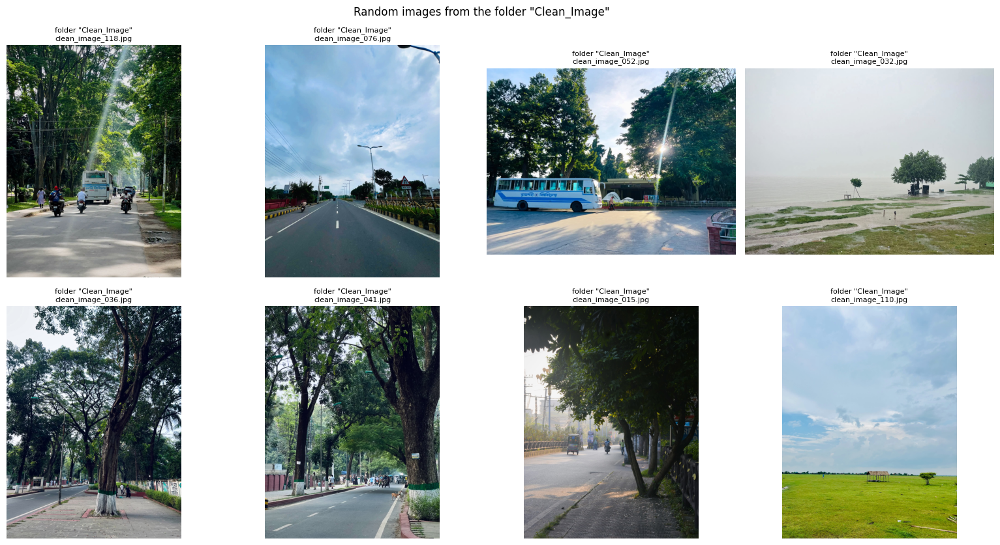

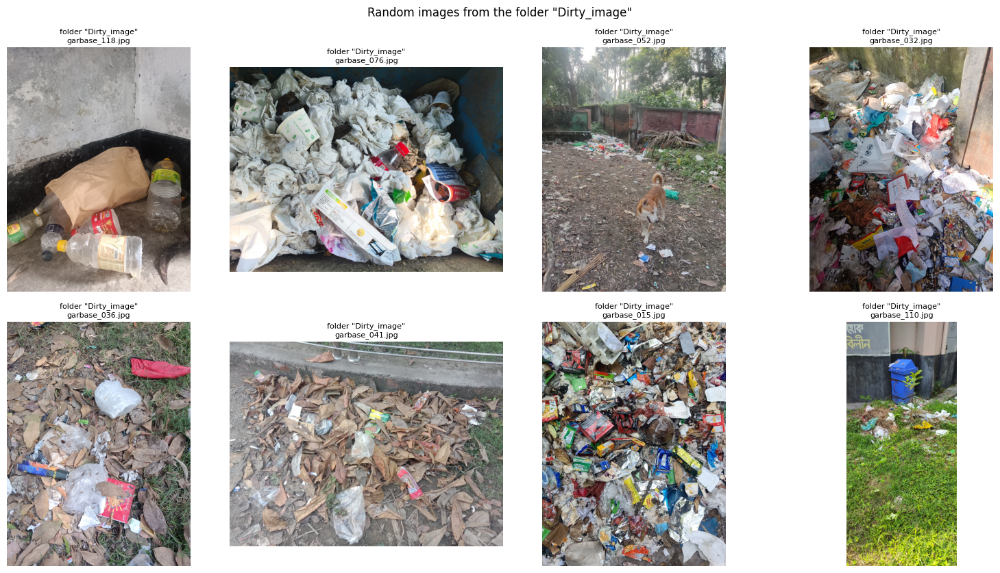

In [41]:
for folder in (CLEAN_DIR.name, DIRTY_DIR.name):
    sub = DF[DF.folder == folder].sample(8, random_state=1)
    fig, axs = plt.subplots(2, 4, figsize=(16, 8.5))
    for ax, (_, r) in zip(axs.ravel(), sub.iterrows()):
        im, _ = read_image(r.path); ax.imshow(im); ax.axis('off'); ax.set_title(f'folder "{folder}"\n{r["name"]}', fontsize=8)
    plt.suptitle(f'Random images from the folder "{folder}"'); plt.tight_layout(); savefig(f'samples_folder_{folder}'); plt.show()

### 1.3 Label check: do file names agree with folder names?

In the listing you sent, the first file of `Dirty_image` is called `clean-image_001` and the first file of `Clean_Image` is called `garbase_001`. That would mean the **folders are swapped**, or that the listing was printed in a different order. The notebook compares the file-name prefixes with the folder names. A swapped labelling would not change the accuracy numbers, but it would make every confusion matrix, example and sentence in the report wrong, so it must be decided explicitly.

* Look at the two image grids above. If the images in `Dirty_image` are clean places (and the reverse), set `SWAP_FOLDER_LABELS = True` in the settings cell and re-run from there.
* If the images match their folders, set `SWAP_FOLDER_LABELS = False`.
* If you leave it at `None`, the notebook decides only when the file names are uninformative or agree with the folders, and **stops with an error** when they disagree.

In [42]:
def name_prefix(fn): return re.sub(r'[\s_\-]*\d+$', '', Path(fn).stem.lower())
CLEAN_KW = ('clean', 'tidy', 'neat')
DIRTY_KW = ('garb', 'dirt', 'trash', 'waste', 'litter', 'dump', 'mess', 'rubbish', 'filth')
def kw_label(prefix):
    c, d = any(k in prefix for k in CLEAN_KW), any(k in prefix for k in DIRTY_KW)
    return 'Clean' if c and not d else 'Dirty' if d and not c else None

pref = DF.groupby('folder').name.apply(lambda s: Counter(name_prefix(x) for x in s).most_common(3))
print('file-name prefixes per folder:'); print(pref.to_string(), '\n')
name_votes = {f: Counter(kw_label(name_prefix(x)) for x in DF[DF.folder == f].name) for f in DF.folder.unique()}
print('keyword votes per folder:', {k: dict(v) for k, v in name_votes.items()})
def folder_name_label(f):
    v = name_votes[f]; tot = v['Clean'] + v['Dirty']
    return None if tot < 0.8 * sum(v.values()) else ('Clean' if v['Clean'] > v['Dirty'] else 'Dirty')
nm = {f: folder_name_label(f) for f in name_votes}
disagree = [f for f in nm if nm[f] is not None and nm[f] != ('Clean' if 'clean' in f.lower() else 'Dirty')]
print('\nlabel implied by the file names:', nm)

if SWAP_FOLDER_LABELS is None:
    if len(disagree) == len(nm) and all(v is not None for v in nm.values()):
        raise RuntimeError('The file names say the opposite of the folder names in BOTH folders ("%s" holds %s-named files). '
                           'Look at the image grids above and set SWAP_FOLDER_LABELS = True (images match the file names) or False '
                           '(images match the folder names) in the settings cell, then re-run from there.' % (DIRTY_DIR.name, nm.get(DIRTY_DIR.name)))
    SWAP_FOLDER_LABELS = False
    print('Decision: folder names are used as labels (SWAP_FOLDER_LABELS = False).')
else: print('Decision taken by you: SWAP_FOLDER_LABELS =', SWAP_FOLDER_LABELS)
DF['label'] = DF.folder_label.map(lambda v: 1 - v) if SWAP_FOLDER_LABELS else DF.folder_label
DF['class_name'] = DF.label.map(dict(enumerate(CLASS_NAMES)))
print('\nfinal class counts:', DF.class_name.value_counts().to_dict())

file-name prefixes per folder:
folder
Clean_Image    [(clean_image, 155)]
Dirty_image        [(garbase, 155)] 

keyword votes per folder: {'Clean_Image': {'Clean': 155}, 'Dirty_image': {'Dirty': 155}}

label implied by the file names: {'Clean_Image': 'Clean', 'Dirty_image': 'Dirty'}
Decision: folder names are used as labels (SWAP_FOLDER_LABELS = False).

final class counts: {'Clean': 155, 'Dirty': 155}


## 2. Dataset preparation (Task 2)

### 2.1 Capture sessions and a leakage-free split

Photos taken minutes apart often show the same place, so a random image-level split lets a model "recognise the place" in the test set. If the images have EXIF timestamps, they are sorted by time and a **new session starts whenever the gap to the previous photo exceeds `SESSION_GAP_MIN` minutes**. The split then keeps every session in exactly one set and keeps the two classes balanced in each set (`StratifiedGroupKFold`). Without timestamps, a stratified random split is used. Several random draws are tried and the one with the best class balance and sizes is kept.

In [43]:
def make_sessions(df, gap_min):
    """Group id per image from EXIF capture times; images without a time become their own group."""
    t = df.exif_time
    if t.notna().mean() < 0.8: return np.arange(len(df)), 'none (fewer than 80% of the images have a capture time)'
    order = np.argsort(t.fillna(pd.Timestamp.max).values); grp = np.zeros(len(df), int); g = 0; prev = None
    for k in order:
        cur = t.iloc[k]
        if pd.isna(cur): g += 1; grp[k] = g; continue
        if prev is not None and (cur - prev).total_seconds() / 60 > gap_min: g += 1
        grp[k] = g; prev = cur
    return grp, f'EXIF capture time, new session after a gap of more than {gap_min} min'

def make_split(y, groups, seed, test_frac, val_frac, tries=300):
    n = len(y); k1 = max(2, round(1 / test_frac)); k2 = max(2, round((1 - 1 / k1) / val_frac)); best, best_score = None, 1e9
    for t in range(tries):
        rs = seed + t
        tr, te = next(iter(StratifiedGroupKFold(n_splits=k1, shuffle=True, random_state=rs).split(np.zeros(n), y, groups)))
        tr2, va = next(iter(StratifiedGroupKFold(n_splits=k2, shuffle=True, random_state=rs).split(np.zeros(len(tr)), y[tr], groups[tr])))
        tr, va = tr[tr2], tr[va]
        parts = (tr, va, te); frac_target = (1 - test_frac - val_frac, val_frac, test_frac)
        score = sum(abs(len(p) / n - ft) for p, ft in zip(parts, frac_target)) + sum(abs(y[p].mean() - y.mean()) for p in parts)
        if score < best_score: best, best_score = parts, score
    return best

y_all = DF.label.values
GROUPS, group_desc = make_sessions(DF, SESSION_GAP_MIN)
print('grouping:', group_desc, '| number of groups:', len(np.unique(GROUPS)), '| largest group:', Counter(GROUPS).most_common(1)[0][1], 'images')
tr_i, va_i, te_i = make_split(y_all, GROUPS, SEED_SPLIT, TEST_FRAC, VAL_FRAC)
DF['split'] = ''
DF.loc[tr_i, 'split'] = 'train'; DF.loc[va_i, 'split'] = 'val'; DF.loc[te_i, 'split'] = 'test'; DF['group'] = GROUPS
assert not (set(GROUPS[tr_i]) & set(GROUPS[te_i])) and not (set(GROUPS[tr_i]) & set(GROUPS[va_i])) and not (set(GROUPS[va_i]) & set(GROUPS[te_i])), 'a group crosses splits'
TAB = pd.crosstab(DF.split, DF.class_name).reindex(['train', 'val', 'test'])
TAB['total'] = TAB.sum(1); TAB['share %'] = (100 * TAB.total / TAB.total.sum()).round(1); TAB['dirty %'] = (100 * TAB.Dirty / TAB.total).round(1)
display(TAB); TAB.to_csv(DIRS['tables'] / 'dataset_split_table.csv')
TRAIN, VAL, TEST = (DF[DF.split == s].reset_index(drop=True) for s in ('train', 'val', 'test'))
print('split sizes:', len(TRAIN), len(VAL), len(TEST))
if len(TEST) < 60: print(f'NOTE: the test set has only {len(TEST)} images: one image is worth {100 / len(TEST):.1f} accuracy points. Quote confidence intervals and seed variation.')

grouping: none (fewer than 80% of the images have a capture time) | number of groups: 310 | largest group: 1 images


class_name,Clean,Dirty,total,share %,dirty %
split,,,,,
train,111,110,221,71.3,49.8
val,22,22,44,14.2,50.0
test,22,23,45,14.5,51.1


split sizes: 221 44 45
NOTE: the test set has only 45 images: one image is worth 2.2 accuracy points. Quote confidence intervals and seed variation.


### 2.2 Leakage checks after the split

In [44]:
sp = DF.set_index('file_id').split
bad = [(a, b, d) for a, b, d in close if sp[a] != sp[b]]
print('near-duplicate pairs that cross splits:', len(bad), bad[:5])
if DF.exif_time.notna().mean() >= 0.8:
    tt = DF[DF.split == 'train'].exif_time.dropna()
    gaps = [abs((tt - t).dt.total_seconds()).min() / 60 for t in DF[DF.split == 'test'].exif_time.dropna()]
    print(f'time from each TEST image to the nearest TRAIN image (minutes): median {np.median(gaps):.1f}, min {np.min(gaps):.1f} '
          f'(sessions are separated by more than {SESSION_GAP_MIN} min, so the minimum should exceed that)')
# do the splits differ in simple image statistics? (a large difference would be a warning sign)
def quick_stats(fid):
    a = CACHE[fid]; g = cv2.cvtColor(a, cv2.COLOR_RGB2GRAY); return dict(brightness=g.mean() / 255, contrast=g.std() / 255)
QS = pd.DataFrame([quick_stats(f) for f in DF.file_id]); QS['split'] = DF.split.values; QS['class'] = DF.class_name.values
display(QS.groupby(['split', 'class']).mean().round(3))

near-duplicate pairs that cross splits: 2 [('Clean_Image/clean_image_001.jpg', 'Clean_Image/clean_image_008.jpg', 0), ('Dirty_image/garbase_058.jpg', 'Dirty_image/garbase_059.jpg', 1)]


brightness  contrast
split class                      
test  Clean       0.481     0.232
      Dirty       0.475     0.205
train Clean       0.482     0.237
      Dirty       0.475     0.204
val   Clean       0.490     0.237
      Dirty       0.470     0.208

### 2.4 Data pipeline and augmentation

Training images are augmented on the fly with torchvision transforms; validation and test images get only a resize and a centre crop. The choices target what changes between phone photos of the same kind of place:

| Transform | Reason |
|---|---|
| RandomResizedCrop(224, scale 0.5-1) | Different distances and framing; the object that makes a place dirty is not always centred |
| Horizontal flip | Places have no preferred left/right |
| Rotation up to 10 degrees | Hand-held phone tilt |
| Colour jitter (brightness, contrast, saturation, small hue) | Indoor/outdoor light, white balance, different phones |
| Random erasing (p = 0.1) | Occlusion; stops the model from relying on one small patch |

Not used: vertical flips, strong colour changes (colour carries information about dirt), and mix-up/cut-mix (they would mix a clean and a dirty scene in one image with a blended label).

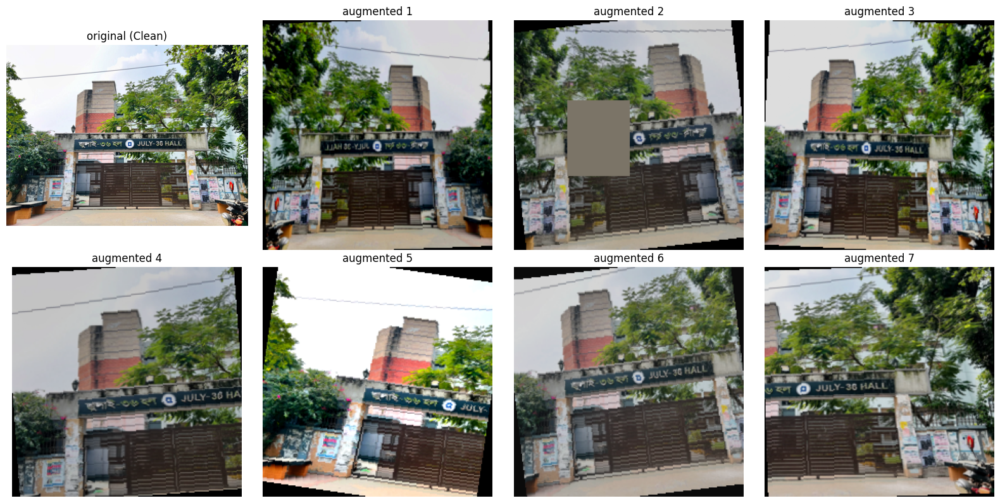

In [45]:
class CDDataset(torch.utils.data.Dataset):
    def __init__(self, df, tf): self.df, self.tf = df.reset_index(drop=True), tf
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]; return self.tf(Image.fromarray(CACHE[r.file_id])), int(r.label), i

def make_tfms(mean, std, size=IMG_SIZE):
    train = T.Compose([T.RandomResizedCrop(size, scale=(0.5, 1.0), ratio=(0.75, 1.33)), T.RandomHorizontalFlip(), T.RandomRotation(10),
                       T.ColorJitter(0.3, 0.3, 0.2, 0.02), T.ToTensor(), T.Normalize(mean, std), T.RandomErasing(p=0.1, scale=(0.02, 0.1))])
    ev = T.Compose([T.Resize(int(size * 256 / 224)), T.CenterCrop(size), T.ToTensor(), T.Normalize(mean, std)])
    return train, ev

# visual check: one image, original and 7 augmentations (de-normalised for display)
IM_MEAN, IM_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
tf_tr, tf_ev = make_tfms(IM_MEAN, IM_STD)
r0 = TRAIN.iloc[0]; img0 = Image.fromarray(CACHE[r0.file_id])
fig, axs = plt.subplots(2, 4, figsize=(16, 8)); axs = axs.ravel()
axs[0].imshow(img0); axs[0].set_title(f'original ({r0.class_name})'); axs[0].axis('off')
inv = lambda t: (t * torch.tensor(IM_STD)[:, None, None] + torch.tensor(IM_MEAN)[:, None, None]).clamp(0, 1).permute(1, 2, 0).numpy()
for k, ax in enumerate(axs[1:]): ax.imshow(inv(tf_tr(img0))); ax.set_title(f'augmented {k + 1}'); ax.axis('off')
plt.tight_layout(); savefig('augmentation_examples'); plt.show()

## 3. Models (Task 3)

All backbones are initialised from ImageNet-pretrained weights and get a new two-class head (randomly initialised). The whole network is fine-tuned.

| Tag | Family | Pretrained weights | Notes |
|---|---|---|---|
| `resnet50` | CNN | `resnet50.a1_in1k` (timm) | Residual blocks, 25.6 M parameters |
| `convnext_tiny` | CNN | `convnext_tiny.fb_in1k` (timm) | CNN with 7x7 depth-wise convolutions, LayerNorm, GELU |
| `vit_small` | Transformer | `vit_small_patch16_224.augreg_in21k_ft_in1k` (timm) | 16x16 patches, global self-attention in every block |
| `swin_tiny` | Transformer | `swin_tiny_patch4_window7_224.ms_in1k` (timm) | Hierarchical, shifted-window attention |
| `mambavision_t` | Mamba (hybrid) | `nvidia/MambaVision-T-1K` (Hugging Face) | Convolutional stages 1-2; stages 3-4 use Mamba mixers in the first half of the blocks and self-attention in the second half |

### 3.1 The Mamba backbone without compiled kernels

`MambaVision` calls one function from the `mamba-ssm` package, `selective_scan_fn`. This is the Mamba recurrence

$$h_t = \exp(\Delta_t A)\,h_{t-1} + \Delta_t B_t u_t, \qquad y_t = C_t h_t + D u_t ,$$

where $\Delta_t$, $B_t$, $C_t$ depend on the input (that is what makes the state-space layer "selective"). The compiled CUDA version runs this scan in parallel. The code below provides the same function in plain PyTorch (a loop over the sequence). The official model file is downloaded from the Hugging Face repository at run time and executed unchanged except for two text edits (the relative import of the config class is replaced, and the Hugging Face wrapper classes at the end of the file are cut off because only the `MambaVision` network itself is needed). The pretrained weights are loaded from the repository's `model.safetensors`.

A self-test compares the loop implementation with an independent closed-form computation on random tensors, so an indexing mistake would be caught before training.

In [46]:
def selective_scan_torch(u, delta, A, B, C, D=None, z=None, delta_bias=None, delta_softplus=False, return_last_state=False):
    """Pure-PyTorch selective scan with the interface of mamba_ssm's selective_scan_fn.
    u, delta: (b, d, l); A: (d, n); B, C: (b, n, l) [or (b, g, n, l)]; D: (d,); z: (b, d, l) optional."""
    dtype_in = u.dtype; cdt = torch.float64 if u.dtype == torch.float64 else torch.float32
    u = u.to(cdt); delta = delta.to(cdt)
    if delta_bias is not None: delta = delta + delta_bias.to(cdt)[None, :, None]
    if delta_softplus: delta = F.softplus(delta)
    b, d, l = u.shape; n = A.shape[1]; A, B, C = A.to(cdt), B.to(cdt), C.to(cdt)
    if B.dim() == 4: B = B.repeat_interleave(d // B.shape[1], dim=1)          # (b, d, n, l)
    if C.dim() == 4: C = C.repeat_interleave(d // C.shape[1], dim=1)
    deltaA = torch.exp(delta.unsqueeze(-1) * A[None, :, None, :])             # (b, d, l, n)
    if B.dim() == 3: dBu = delta.unsqueeze(-1) * B.permute(0, 2, 1).unsqueeze(1) * u.unsqueeze(-1)
    else:            dBu = delta.unsqueeze(-1) * B.permute(0, 1, 3, 2) * u.unsqueeze(-1)
    x = u.new_zeros((b, d, n)); ys = []
    for i in range(l):
        x = deltaA[:, :, i] * x + dBu[:, :, i]
        ys.append(torch.einsum('bdn,bn->bd', x, C[:, :, i]) if C.dim() == 3 else torch.einsum('bdn,bdn->bd', x, C[:, :, :, i]))
    y = torch.stack(ys, dim=2)
    out = y if D is None else y + u * D.to(cdt)[None, :, None]
    if z is not None: out = out * F.silu(z.to(cdt))
    out = out.to(dtype_in)
    return (out, x) if return_last_state else out

def _scan_selftest():
    g = torch.Generator().manual_seed(0); b, d, n, l = 2, 5, 4, 9
    u = torch.randn(b, d, l, generator=g, dtype=torch.float64); dl = torch.randn(b, d, l, generator=g, dtype=torch.float64)
    A = -torch.rand(d, n, generator=g, dtype=torch.float64) - 0.1; B = torch.randn(b, n, l, generator=g, dtype=torch.float64)
    C = torch.randn(b, n, l, generator=g, dtype=torch.float64); D = torch.randn(d, generator=g, dtype=torch.float64); bias = torch.randn(d, generator=g, dtype=torch.float64)
    got = selective_scan_torch(u, dl, A, B, C, D, delta_bias=bias, delta_softplus=True).double()
    dlt = F.softplus(dl + bias[None, :, None]); ref = torch.zeros(b, d, l, dtype=torch.float64)       # closed form: h_t = sum_s prod_{s<r<=t} exp(dlt_r A) * dlt_s B_s u_s
    for t in range(l):
        h = torch.zeros(b, d, n, dtype=torch.float64)
        for s in range(t + 1):
            decay = torch.ones(b, d, n, dtype=torch.float64)
            for r in range(s + 1, t + 1): decay = decay * torch.exp(dlt[:, :, r, None] * A[None])
            h = h + decay * dlt[:, :, s, None] * B[:, None, :, s] * u[:, :, s, None]
        ref[:, :, t] = (h * C[:, None, :, t]).sum(-1) + D[None] * u[:, :, t]
    err = (got - ref).abs().max().item(); print(f'selective-scan self-test: max abs difference {err:.2e} (should be < 1e-8)'); assert err < 1e-8
_scan_selftest()

selective-scan self-test: max abs difference 1.78e-15 (should be < 1e-8)


In [47]:
def install_scan_stub():
    """Make `from mamba_ssm.ops.selective_scan_interface import selective_scan_fn` work without the compiled package."""
    try:
        from mamba_ssm.ops.selective_scan_interface import selective_scan_fn          # real CUDA kernels, if installed
        return 'mamba_ssm CUDA kernels'
    except Exception: pass
    class _Stub(types.ModuleType):
        def __getattr__(self, name): raise AttributeError(f'{self.__name__}.{name} is not provided by the pure-PyTorch stub')
    pkg, ops, ssi = _Stub('mamba_ssm'), _Stub('mamba_ssm.ops'), _Stub('mamba_ssm.ops.selective_scan_interface')
    pkg.__path__, ops.__path__ = [], []
    ssi.selective_scan_fn = selective_scan_torch; ssi.selective_scan_ref = selective_scan_torch; pkg.ops = ops; ops.selective_scan_interface = ssi
    sys.modules.update({'mamba_ssm': pkg, 'mamba_ssm.ops': ops, 'mamba_ssm.ops.selective_scan_interface': ssi})
    return 'pure-PyTorch scan (no CUDA kernels)'

def _ensure_timm_shims():
    """The official file imports from deprecated timm paths; provide them if the installed timm no longer has them."""
    try: import timm.models.layers
    except Exception: sys.modules['timm.models.layers'] = importlib.import_module('timm.layers')
    try: import timm.models.registry
    except Exception:
        m = types.ModuleType('timm.models.registry'); m.register_model = lambda fn=None, *a, **k: fn; sys.modules['timm.models.registry'] = m

MV_REPO = 'nvidia/MambaVision-T-1K'
SCAN_IMPL = None
def load_mambavision_net():
    """Return the pretrained official MambaVision-T network (feature extractor with a 1000-class head that we replace)."""
    global SCAN_IMPL
    from huggingface_hub import hf_hub_download
    from safetensors.torch import load_file
    SCAN_IMPL = install_scan_stub(); _ensure_timm_shims()
    code = open(hf_hub_download(MV_REPO, 'modeling_mambavision.py')).read()
    assert 'from .configuration_mambavision import MambaVisionConfig' in code and 'class MambaVisionModel(PreTrainedModel):' in code, 'the official file changed'
    code = code.replace('from .configuration_mambavision import MambaVisionConfig', 'MambaVisionConfig = None').split('class MambaVisionModel(PreTrainedModel):')[0]
    ns = {'__name__': 'mambavision_official'}; exec(compile(code, 'modeling_mambavision.py', 'exec'), ns)
    cfg = json.load(open(hf_hub_download(MV_REPO, 'config.json')))
    kw = dict(depths=cfg.get('depths', [1, 3, 8, 4]), num_heads=cfg.get('num_heads', [2, 4, 8, 16]), window_size=cfg.get('window_size', [8, 8, 14, 7]),
              dim=cfg.get('dim', 80), in_dim=cfg.get('in_dim', 32), mlp_ratio=cfg.get('mlp_ratio', 4))
    net = ns['MambaVision'](**kw)
    sd = load_file(hf_hub_download(MV_REPO, 'model.safetensors')); sd = {(k[len('model.'):] if k.startswith('model.') else k): v for k, v in sd.items()}
    missing, unexpected = net.load_state_dict(sd, strict=False)
    non_head_missing = [k for k in missing if not k.startswith('head.')]
    print(f'MambaVision-T weights loaded | scan: {SCAN_IMPL} | missing (non-head): {len(non_head_missing)} | unexpected: {len(unexpected)}')
    assert len(non_head_missing) == 0, f'pretrained weights do not match the network: {non_head_missing[:5]}'
    return net

class MambaVisionClassifier(nn.Module):
    def __init__(self, net, num_classes=2, drop=0.2):
        super().__init__(); self.net = net; self.net.head = nn.Identity()
        self.drop = nn.Dropout(drop); self.fc = nn.Linear(net.norm.num_features, num_classes)
    def forward(self, x):
        feat, _ = self.net.forward_features(x); return self.fc(self.drop(feat))

In [48]:
MODELS = {
    'resnet50':      dict(family='CNN',            source='timm', name='resnet50.a1_in1k',                                lr=1e-4, label='ResNet-50'),
    'convnext_tiny': dict(family='CNN',            source='timm', name='convnext_tiny.fb_in1k',                           lr=1e-4, label='ConvNeXt-T'),
    'vit_small':     dict(family='Transformer',    source='timm', name='vit_small_patch16_224.augreg_in21k_ft_in1k',      lr=5e-5, label='ViT-S/16'),
    'swin_tiny':     dict(family='Transformer',    source='timm', name='swin_tiny_patch4_window7_224.ms_in1k',            lr=5e-5, label='Swin-T'),
    'mambavision_t': dict(family='Mamba (hybrid)', source='mambavision',                                                  lr=1e-4, label='MambaVision-T'),
}
RUN_MODELS = ['resnet50', 'convnext_tiny', 'vit_small', 'swin_tiny', 'mambavision_t']
HEAD_LR_MULT = 10          # the new head learns 10x faster than the pretrained backbone

def build_model(tag):
    """Returns model (on DEVICE), normalisation info and the parameters of the new head."""
    spec = MODELS[tag]
    if spec['source'] == 'timm':
        m = timm.create_model(spec['name'], pretrained=True, num_classes=2)
        cfg = timm.data.resolve_data_config({}, model=m); info = dict(mean=cfg['mean'], std=cfg['std'])
        head = list(m.get_classifier().parameters())
    elif spec['source'] == 'mambavision':
        m = MambaVisionClassifier(load_mambavision_net()); info = dict(mean=IM_MEAN, std=IM_STD); head = list(m.fc.parameters())
    return m.to(DEVICE), info, head

def count_flops(model, size=IMG_SIZE):
    from torch.utils.flop_counter import FlopCounterMode
    model.eval(); x = torch.randn(1, 3, size, size, device=DEVICE)
    with FlopCounterMode(display=False) as fc, torch.no_grad(): model(x)
    return fc.get_total_flops() / 1e9

# ---- build every model once: load pretrained weights, check a forward pass, count parameters and FLOPs ----
rows = []
for tag in RUN_MODELS:
    try:
        m, info, head = build_model(tag)
        with torch.no_grad(): out = m.eval()(torch.randn(2, 3, IMG_SIZE, IMG_SIZE, device=DEVICE))
        assert out.shape == (2, 2), out.shape
        p = sum(q.numel() for q in m.parameters()) / 1e6
        try: gf = count_flops(m)
        except Exception as e: gf = float('nan'); print('  FLOP count failed for', tag, str(e)[:80])
        rows.append(dict(tag=tag, model=MODELS[tag]['label'], family=MODELS[tag]['family'], params_M=round(p, 2), GFLOPs=round(gf, 2), fp32_size_MB=round(p * 4, 1)))
        del m; gc.collect(); torch.cuda.empty_cache()
    except Exception as e:
        print(f'!! {tag} could not be built: {type(e).__name__}: {str(e)[:300]}')
        if tag == 'mambavision_t':
            print('   -> falling back to MambaOut-Tiny (timm). It belongs to the "Mamba family" by name but contains NO state-space layer; say so in the report.')
            MODELS['mambavision_t'] = dict(family='Mamba-family (MambaOut, no SSM)', source='timm', name='mambaout_tiny.in1k', lr=1e-4, label='MambaOut-T (fallback)')
            m, info, head = build_model('mambavision_t'); p = sum(q.numel() for q in m.parameters()) / 1e6
            rows.append(dict(tag=tag, model=MODELS[tag]['label'], family=MODELS[tag]['family'], params_M=round(p, 2), GFLOPs=round(count_flops(m), 2), fp32_size_MB=round(p * 4, 1)))
            del m; gc.collect(); torch.cuda.empty_cache()
RUN_MODELS = [t for t in RUN_MODELS if t in {r['tag'] for r in rows}]
MODEL_TABLE = pd.DataFrame(rows).set_index('tag'); display(MODEL_TABLE); MODEL_TABLE.to_csv(DIRS['tables'] / 'model_overview.csv')
print('GFLOPs are counted by torch.utils.flop_counter (matrix multiplications, convolutions, attention). Element-wise operations, including the Mamba scan, are not counted,')
print('so the FLOPs of the Mamba model are under-estimated; latency (Section 6) is the more honest cost measure.')

MambaVision-T weights loaded | scan: mamba_ssm CUDA kernels | missing (non-head): 0 | unexpected: 0


,model,family,params_M,GFLOPs,fp32_size_MB
tag,,,,,
resnet50,ResNet-50,CNN,23.51,8.17,94.0
convnext_tiny,ConvNeXt-T,CNN,27.82,8.91,111.3
vit_small,ViT-S/16,Transformer,21.67,9.20,86.7
swin_tiny,Swin-T,Transformer,27.52,8.98,110.1
mambavision_t,MambaVision-T,Mamba (hybrid),31.15,9.13,124.6


GFLOPs are counted by torch.utils.flop_counter (matrix multiplications, convolutions, attention). Element-wise operations, including the Mamba scan, are not counted,
so the FLOPs of the Mamba model are under-estimated; latency (Section 6) is the more honest cost measure.


## 4. Fine-tuning (Task 3)

One training loop serves every model.

* **Optimiser:** AdamW, weight decay 0.05, learning rate per model (table above) for the pretrained backbone and 10 times that for the new head, linear warm-up for 2 epochs, then cosine decay to 5 % of the learning rate, gradient clipping at 1.0, label smoothing 0.1, mixed precision (FP16 autocast).
* **Batch size 16, at most 30 epochs.** After every epoch the model is evaluated on the **validation** set. The checkpoint with the best validation macro-F1 (ties broken by the lower validation loss) is kept, and training stops after 8 epochs without improvement.
* **The test set is never used** to choose a checkpoint, an epoch, a learning rate or a threshold.
* The learning rates are common defaults for fine-tuning, **not tuned values**; all models get the same recipe so that the comparison is about the backbones and not about tuning effort.
* The notebook trains every model with each seed in `SEEDS` and stores the best weights in Drive; models that already exist are skipped.

In [49]:
CFG = dict(epochs=2 if QUICK_TEST else 30, bs=16, wd=0.05, warmup_epochs=2, patience=8, label_smoothing=0.1, clip=1.0, amp=True, num_workers=2)
display(pd.DataFrame({'setting': list(CFG), 'value': list(CFG.values())}).set_index('setting').T)

def make_loaders(info, bs=CFG['bs']):
    tr_tf, ev_tf = make_tfms(info['mean'], info['std'])
    mk = lambda df, tf, shuf: torch.utils.data.DataLoader(CDDataset(df, tf), batch_size=bs, shuffle=shuf, num_workers=CFG['num_workers'], drop_last=False)
    return mk(TRAIN, tr_tf, True), mk(VAL, ev_tf, False), mk(TEST, ev_tf, False)

@torch.no_grad()
def predict_loader(model, loader, amp=False):
    model.eval(); P, Y, L = [], [], 0.0
    for x, y, _ in loader:
        x = x.to(DEVICE, non_blocking=True)
        with torch.autocast('cuda', dtype=torch.float16, enabled=amp): lo = model(x)
        lo = lo.float(); L += F.cross_entropy(lo, y.to(DEVICE), reduction='sum').item()
        P.append(lo.softmax(-1).cpu().numpy()); Y.append(y.numpy())
    return np.concatenate(P), np.concatenate(Y), L / len(loader.dataset)

def macro_f1(y, p): return precision_recall_fscore_support(y, p.argmax(1), average='macro', zero_division=0)[2]

def ckpt_path(tag, seed): return DIRS['models'] / f'{tag}_seed{seed}.pt'

def train_one(tag, seed):
    spec = MODELS[tag]; seed_everything(seed)
    model, info, head = build_model(tag); head_ids = {id(p) for p in head}
    groups = [dict(params=[p for p in model.parameters() if id(p) not in head_ids], lr=spec['lr']), dict(params=head, lr=spec['lr'] * HEAD_LR_MULT)]
    for g in groups: g['base_lr'] = g['lr']
    opt = torch.optim.AdamW(groups, weight_decay=CFG['wd'])
    trl, val, _ = make_loaders(info); spe = len(trl); total = CFG['epochs'] * spe; warm = CFG['warmup_epochs'] * spe
    scale = lambda s: min(1.0, (s + 1) / warm) * (0.05 + 0.95 * 0.5 * (1 + math.cos(math.pi * min(1.0, s / total))))
    scaler = torch.amp.GradScaler('cuda', enabled=CFG['amp']); crit = nn.CrossEntropyLoss(label_smoothing=CFG['label_smoothing'])
    hist, best, bad, step = [], (-1.0, 1e9), 0, 0; torch.cuda.reset_peak_memory_stats(); t_start = perf_counter(); epoch_times = []
    for ep in range(1, CFG['epochs'] + 1):
        model.train(); t0 = perf_counter(); run, n = 0.0, 0
        for x, y, _ in trl:
            for g in opt.param_groups: g['lr'] = g['base_lr'] * scale(step)
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            with torch.autocast('cuda', dtype=torch.float16, enabled=CFG['amp']): loss = crit(model(x).float(), y)
            if not torch.isfinite(loss): opt.zero_grad(set_to_none=True); step += 1; continue
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG['clip']); scaler.step(opt); scaler.update(); step += 1
            run += loss.item() * len(y); n += len(y)
        torch.cuda.synchronize(); epoch_times.append(perf_counter() - t0)
        pv, yv, lv = predict_loader(model, val); f1 = macro_f1(yv, pv); acc = accuracy_score(yv, pv.argmax(1))
        hist.append(dict(epoch=ep, train_loss=run / max(n, 1), val_loss=lv, val_acc=acc, val_macro_f1=f1, lr=opt.param_groups[0]['lr'], epoch_time_s=epoch_times[-1]))
        if (f1, -lv) > (best[0], -best[1]): best, bad = (f1, lv), 0; torch.save(model.state_dict(), ckpt_path(tag, seed)); hist[-1]['best'] = True
        else: bad += 1
        if bad >= CFG['patience']: break
    H = pd.DataFrame(hist); H.to_csv(DIRS['histories'] / f'{tag}_seed{seed}.csv', index=False)
    info_run = dict(tag=tag, seed=seed, epochs_run=len(H), best_epoch=int(H.loc[H.get('best', False) == True, 'epoch'].max()), train_time_min=(perf_counter() - t_start) / 60,
                    mean_epoch_s=float(np.mean(epoch_times)), train_peak_MB=torch.cuda.max_memory_allocated() / 2**20)
    json.dump(info_run, open(DIRS['histories'] / f'{tag}_seed{seed}_summary.json', 'w'))
    del model, opt; gc.collect(); torch.cuda.empty_cache(); return H, info_run

TRAIN_INFO = {}
for tag in RUN_MODELS:
    for seed in SEEDS:
        sj = DIRS['histories'] / f'{tag}_seed{seed}_summary.json'
        if ckpt_path(tag, seed).exists() and sj.exists() and not QUICK_TEST:
            TRAIN_INFO[(tag, seed)] = json.load(open(sj)); print(f'{tag} seed {seed}: checkpoint exists, skipping training'); continue
        try:
            H, TRAIN_INFO[(tag, seed)] = train_one(tag, seed); i = TRAIN_INFO[(tag, seed)]
            print(f"{MODELS[tag]['label']:14s} seed {seed}: {i['epochs_run']:2d} epochs (best {i['best_epoch']:2d}) | val macro-F1 {H.val_macro_f1.max():.3f} | {i['train_time_min']:.1f} min | {i['train_peak_MB']:.0f} MB")
        except Exception as e:
            print(f'!! training {tag} seed {seed} failed: {type(e).__name__}: {str(e)[:300]}'); gc.collect(); torch.cuda.empty_cache()

setting,epochs,bs,wd,warmup_epochs,patience,label_smoothing,clip,amp,num_workers
value,30,16,0.05,2,8,0.1,1.0,True,2


ResNet-50      seed 42: 30 epochs (best 30) | val macro-F1 1.000 | 1.6 min | 1121 MB
ResNet-50      seed 43: 15 epochs (best  7) | val macro-F1 1.000 | 0.8 min | 1122 MB
ResNet-50      seed 44: 27 epochs (best 19) | val macro-F1 1.000 | 1.3 min | 1122 MB
ConvNeXt-T     seed 42: 10 epochs (best  2) | val macro-F1 1.000 | 0.5 min | 1475 MB
ConvNeXt-T     seed 43: 10 epochs (best  2) | val macro-F1 1.000 | 0.5 min | 1472 MB
ConvNeXt-T     seed 44: 10 epochs (best  2) | val macro-F1 1.000 | 0.5 min | 1477 MB
ViT-S/16       seed 42: 13 epochs (best  5) | val macro-F1 1.000 | 0.6 min | 937 MB
ViT-S/16       seed 43: 11 epochs (best  3) | val macro-F1 1.000 | 0.6 min | 938 MB
ViT-S/16       seed 44:  9 epochs (best  1) | val macro-F1 1.000 | 0.4 min | 937 MB
Swin-T         seed 42: 18 epochs (best 10) | val macro-F1 1.000 | 1.0 min | 1601 MB
Swin-T         seed 43: 11 epochs (best  3) | val macro-F1 1.000 | 0.6 min | 1596 MB
Swin-T         seed 44: 15 epochs (best  7) | val macro-F1 1.000 | 0

### 4.1 Training curves

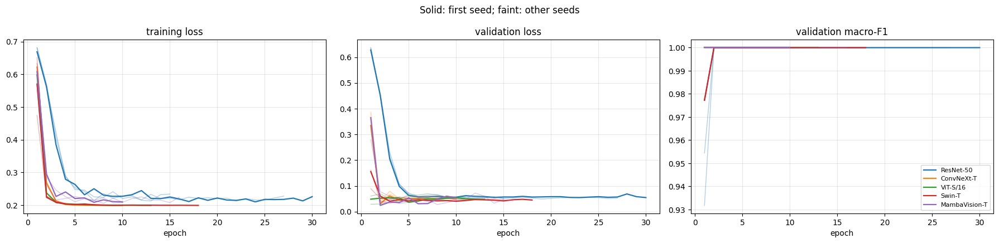

In [50]:
fig, axs = plt.subplots(1, 3, figsize=(18, 4.4)); cols = plt.cm.tab10.colors
for k, tag in enumerate(RUN_MODELS):
    for seed in SEEDS:
        p = DIRS['histories'] / f'{tag}_seed{seed}.csv'
        if not p.exists(): continue
        H = pd.read_csv(p); kw = dict(color=cols[k], alpha=1.0 if seed == SEEDS[0] else 0.35, lw=1.6 if seed == SEEDS[0] else 1.0, label=MODELS[tag]['label'] if seed == SEEDS[0] else None)
        axs[0].plot(H.epoch, H.train_loss, **kw); axs[1].plot(H.epoch, H.val_loss, **kw); axs[2].plot(H.epoch, H.val_macro_f1, **kw)
for a, t in zip(axs, ['training loss', 'validation loss', 'validation macro-F1']): a.set_title(t); a.set_xlabel('epoch'); a.grid(alpha=.3)
axs[2].legend(fontsize=8); plt.suptitle('Solid: first seed; faint: other seeds'); plt.tight_layout(); savefig('training_curves'); plt.show()

## 5. Performance evaluation (Task 4)

Every model is evaluated on the same **test images** with the same code, using the checkpoint with the best **validation** macro-F1.

* **Accuracy**, **precision**, **recall**, **F1** for the positive class *Dirty*: precision = TP/(TP+FP) is the share of images called dirty that are dirty, recall = TP/(TP+FN) is the share of dirty images that are found. **Macro** values average the two classes. Balanced accuracy is the mean of the two recalls.
* **Confusion matrices** (counts and row-normalised).
* **ROC-AUC** and average precision use the predicted probability of *Dirty* and do not depend on the 0.5 threshold. **Brier score** and **expected calibration error (ECE, 10 bins)** measure how trustworthy the probabilities are.
* **Uncertainty:** every number is the mean and standard deviation over the training seeds, the accuracy of the first seed also has a 95 % Wilson confidence interval, and a bootstrap interval over test images is given for accuracy and F1.
* **Significance of differences:** McNemar's exact test on the test images that two models classify differently (first seed).
* All predictions use the default threshold 0.5 on the softmax probability.

In [51]:
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z * z / n; c = (p + z * z / (2 * n)) / d; h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d; return (c - h, c + h)

def ece_score(y, p, bins=10):
    conf = p.max(1); pred = p.argmax(1); acc = (pred == y).astype(float); e = 0.0
    for lo in np.linspace(0, 1, bins, endpoint=False):
        m = (conf > lo) & (conf <= lo + 1 / bins)
        if m.any(): e += m.mean() * abs(acc[m].mean() - conf[m].mean())
    return e

def clf_metrics(y, p):
    pred = p.argmax(1); pd_ = p[:, 1]
    pr, rc, f1, _ = precision_recall_fscore_support(y, pred, labels=[0, 1], zero_division=0)
    mp, mr, mf, _ = precision_recall_fscore_support(y, pred, average='macro', zero_division=0)
    both = len(set(y)) > 1
    return dict(accuracy=accuracy_score(y, pred), balanced_acc=balanced_accuracy_score(y, pred), precision=pr[1], recall=rc[1], f1=f1[1],
                precision_clean=pr[0], recall_clean=rc[0], f1_clean=f1[0], macro_precision=mp, macro_recall=mr, macro_f1=mf,
                auc=roc_auc_score(y, pd_) if both else np.nan, avg_precision=average_precision_score(y, pd_) if both else np.nan,
                brier=brier_score_loss(y, pd_), ece=ece_score(y, p))

def bootstrap_ci(y, p, fn, n=2000, seed=0):
    rng = np.random.default_rng(seed); out = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if len(set(y[i])) < 2: continue
        out.append(fn(y[i], p[i]))
    return tuple(np.percentile(out, [2.5, 97.5]))

PRED = {}      # (tag, seed) -> dict(pv, yv, pt, yt)
for tag in RUN_MODELS:
    for seed in SEEDS:
        if not ckpt_path(tag, seed).exists(): print(f'no checkpoint for {tag} seed {seed}, skipped'); continue
        try:
            model, info, _ = build_model(tag); model.load_state_dict(torch.load(ckpt_path(tag, seed), map_location=DEVICE))
            _, vl, tl = make_loaders(info); pv, yv, _ = predict_loader(model, vl); pt, yt, _ = predict_loader(model, tl)
            PRED[(tag, seed)] = dict(pv=pv, yv=yv, pt=pt, yt=yt); np.savez(DIRS['predictions'] / f'{tag}_seed{seed}.npz', pv=pv, yv=yv, pt=pt, yt=yt)
            del model; gc.collect(); torch.cuda.empty_cache()
        except Exception as e: print(f'!! evaluation of {tag} seed {seed} failed: {type(e).__name__}: {str(e)[:200]}')
TAGS = [t for t in RUN_MODELS if any((t, s) in PRED for s in SEEDS)]
S0 = SEEDS[0]
assert (TAGS and all((t, S0) in PRED for t in TAGS)), 'models for the first seed are missing'
assert all((PRED[(t, S0)]['yt'] == PRED[(TAGS[0], S0)]['yt']).all() for t in TAGS)
YT = PRED[(TAGS[0], S0)]['yt']
print('test images:', len(YT), '| dirty:', int(YT.sum()), '| clean:', int((1 - YT).sum()))

PER_RUN = pd.DataFrame([dict(tag=t, model=MODELS[t]['label'], family=MODELS[t]['family'], seed=s, split=sp, **clf_metrics(PRED[(t, s)]['y' + sp[0]], PRED[(t, s)]['p' + sp[0]]))
                        for (t, s) in PRED for sp in ('val', 'test')])
PER_RUN.to_csv(DIRS['tables'] / 'metrics_per_run.csv', index=False)
KEYS = ['accuracy', 'precision', 'recall', 'f1', 'macro_f1', 'balanced_acc', 'auc', 'brier', 'ece']
def summarise(split):
    g = PER_RUN[PER_RUN.split == split].groupby('tag')[KEYS]; m, s = g.mean(), g.std(ddof=0).fillna(0)
    out = pd.DataFrame({k: [f'{m.loc[t, k]:.3f} ± {s.loc[t, k]:.3f}' for t in TAGS] for k in KEYS}, index=[MODELS[t]['label'] for t in TAGS])
    out.insert(0, 'family', [MODELS[t]['family'] for t in TAGS]); out.insert(1, 'seeds', [int((PER_RUN[(PER_RUN.split == split) & (PER_RUN.tag == t)]).shape[0]) for t in TAGS]); return out, m
SUM_TEST, MEAN_TEST = summarise('test'); SUM_VAL, _ = summarise('val')
print('TEST set: mean ± standard deviation over training seeds (positive class = Dirty)'); display(SUM_TEST); SUM_TEST.to_csv(DIRS['tables'] / 'results_test_mean_std.csv')
print('VALIDATION set (used for checkpoint selection)'); display(SUM_VAL); SUM_VAL.to_csv(DIRS['tables'] / 'results_val_mean_std.csv')

rows = []
for t in TAGS:
    y, p = YT, PRED[(t, S0)]['pt']; k = int((p.argmax(1) == y).sum()); lo, hi = wilson(k, len(y))
    ba = bootstrap_ci(y, p, lambda a, b: accuracy_score(a, b.argmax(1))); bf = bootstrap_ci(y, p, lambda a, b: precision_recall_fscore_support(a, b.argmax(1), labels=[0, 1], zero_division=0)[2][1])
    rows.append(dict(model=MODELS[t]['label'], correct=f'{k}/{len(y)}', accuracy=k / len(y), wilson_95=f'[{lo:.3f}, {hi:.3f}]', boot_acc_95=f'[{ba[0]:.3f}, {ba[1]:.3f}]', boot_f1_95=f'[{bf[0]:.3f}, {bf[1]:.3f}]'))
CI = pd.DataFrame(rows).set_index('model'); print(f'Confidence intervals for the first seed ({S0}), test set'); display(CI.round(3)); CI.to_csv(DIRS['tables'] / 'confidence_intervals_seed0.csv')

MambaVision-T weights loaded | scan: mamba_ssm CUDA kernels | missing (non-head): 0 | unexpected: 0
MambaVision-T weights loaded | scan: mamba_ssm CUDA kernels | missing (non-head): 0 | unexpected: 0
MambaVision-T weights loaded | scan: mamba_ssm CUDA kernels | missing (non-head): 0 | unexpected: 0
test images: 45 | dirty: 23 | clean: 22
TEST set: mean ± standard deviation over training seeds (positive class = Dirty)


,family,seeds,accuracy,precision,recall,f1,macro_f1,balanced_acc,auc,brier,ece
ResNet-50,CNN,3,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,0.004 ± 0.001,0.054 ± 0.003
ConvNeXt-T,CNN,3,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,0.003 ± 0.001,0.040 ± 0.005
ViT-S/16,Transformer,3,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,0.003 ± 0.001,0.042 ± 0.007
Swin-T,Transformer,3,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,0.003 ± 0.000,0.044 ± 0.001
MambaVision-T,Mamba (hybrid),3,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,0.002 ± 0.001,0.032 ± 0.002


VALIDATION set (used for checkpoint selection)


,family,seeds,accuracy,precision,recall,f1,macro_f1,balanced_acc,auc,brier,ece
ResNet-50,CNN,3,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,0.004 ± 0.000,0.049 ± 0.002
ConvNeXt-T,CNN,3,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,0.002 ± 0.000,0.034 ± 0.004
ViT-S/16,Transformer,3,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,0.002 ± 0.001,0.037 ± 0.008
Swin-T,Transformer,3,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,0.002 ± 0.000,0.038 ± 0.004
MambaVision-T,Mamba (hybrid),3,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,0.001 ± 0.000,0.027 ± 0.003


Confidence intervals for the first seed (42), test set


,correct,accuracy,wilson_95,boot_acc_95,boot_f1_95
model,,,,,
ResNet-50,45/45,1.0,"[0.921, 1.000]","[1.000, 1.000]","[1.000, 1.000]"
ConvNeXt-T,45/45,1.0,"[0.921, 1.000]","[1.000, 1.000]","[1.000, 1.000]"
ViT-S/16,45/45,1.0,"[0.921, 1.000]","[1.000, 1.000]","[1.000, 1.000]"
Swin-T,45/45,1.0,"[0.921, 1.000]","[1.000, 1.000]","[1.000, 1.000]"
MambaVision-T,45/45,1.0,"[0.921, 1.000]","[1.000, 1.000]","[1.000, 1.000]"


### 5.1 Confusion matrices (first seed)

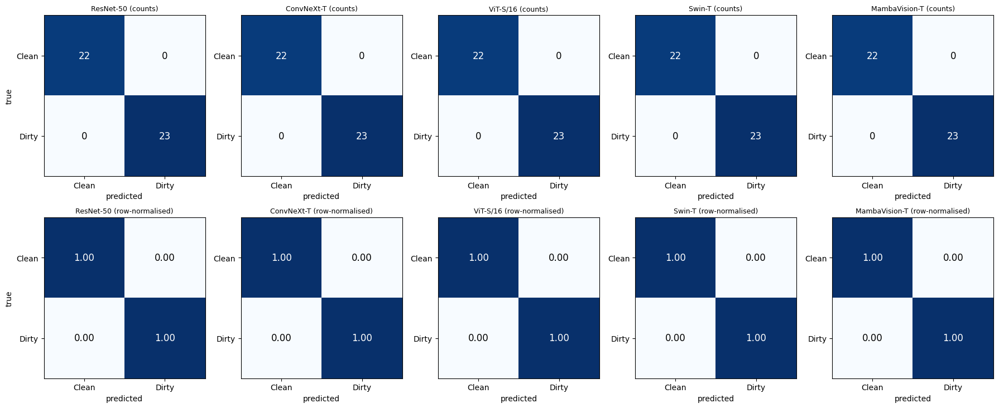

,TN,FP,FN,TP
model,,,,
ResNet-50,22,0,0,23
ConvNeXt-T,22,0,0,23
ViT-S/16,22,0,0,23
Swin-T,22,0,0,23
MambaVision-T,22,0,0,23


FP = clean place called dirty; FN = dirty place called clean (a missed dirty place).


In [52]:
n = len(TAGS); fig, axs = plt.subplots(2, n, figsize=(3.6 * n, 7.4), squeeze=False)
for j, t in enumerate(TAGS):
    cm = confusion_matrix(YT, PRED[(t, S0)]['pt'].argmax(1), labels=[0, 1]); cmn = cm / cm.sum(1, keepdims=True)
    for i, (mat, fmt, ttl) in enumerate(((cm, '{:d}', 'counts'), (cmn, '{:.2f}', 'row-normalised'))):
        ax = axs[i, j]; ax.imshow(mat, cmap='Blues', vmin=0, vmax=mat.max() if i == 0 else 1); ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
        ax.set_xticklabels(CLASS_NAMES); ax.set_yticklabels(CLASS_NAMES); ax.set_xlabel('predicted'); ax.set_ylabel('true' if j == 0 else '')
        for (a, b), v in np.ndenumerate(mat): ax.text(b, a, fmt.format(v), ha='center', va='center', color='white' if v > mat.max() * 0.55 else 'black', fontsize=12)
        ax.set_title(f'{MODELS[t]["label"]} ({ttl})', fontsize=9)
plt.tight_layout(); savefig('confusion_matrices'); plt.show()
cm_rows = []
for t in TAGS:
    cm = confusion_matrix(YT, PRED[(t, S0)]['pt'].argmax(1), labels=[0, 1]); cm_rows.append(dict(model=MODELS[t]['label'], TN=cm[0, 0], FP=cm[0, 1], FN=cm[1, 0], TP=cm[1, 1]))
CM_DF = pd.DataFrame(cm_rows).set_index('model'); display(CM_DF); CM_DF.to_csv(DIRS['tables'] / 'confusion_counts_seed0.csv')
print('FP = clean place called dirty; FN = dirty place called clean (a missed dirty place).')

### 5.2 ROC curves, precision-recall curves and calibration (first seed)

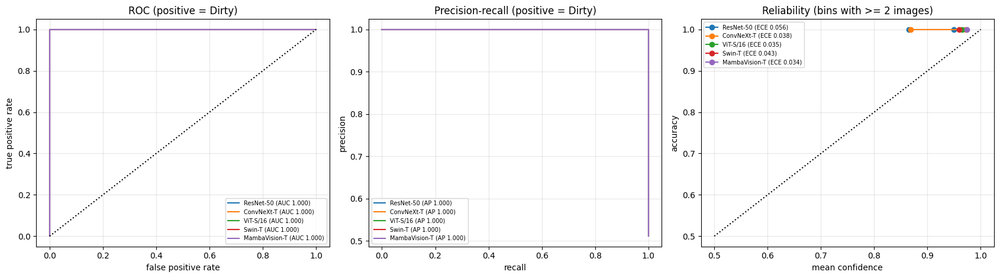

In [53]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.8)); cols = plt.cm.tab10.colors
for k, t in enumerate(TAGS):
    p = PRED[(t, S0)]['pt']; lab = MODELS[t]['label']
    fpr, tpr, _ = roc_curve(YT, p[:, 1]); axs[0].plot(fpr, tpr, color=cols[k], label=f'{lab} (AUC {roc_auc_score(YT, p[:, 1]):.3f})')
    pr_, rc_, _ = precision_recall_curve(YT, p[:, 1]); axs[1].plot(rc_, pr_, color=cols[k], label=f'{lab} (AP {average_precision_score(YT, p[:, 1]):.3f})')
    conf = p.max(1); acc = (p.argmax(1) == YT).astype(float); edges = np.linspace(0.5, 1, 6); xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() >= 2: xs.append(conf[m].mean()); ys.append(acc[m].mean())
    axs[2].plot(xs, ys, 'o-', color=cols[k], label=f'{lab} (ECE {ece_score(YT, p):.3f})')
axs[0].plot([0, 1], [0, 1], 'k:'); axs[0].set_xlabel('false positive rate'); axs[0].set_ylabel('true positive rate'); axs[0].set_title('ROC (positive = Dirty)')
axs[1].set_xlabel('recall'); axs[1].set_ylabel('precision'); axs[1].set_title('Precision-recall (positive = Dirty)')
axs[2].plot([0.5, 1], [0.5, 1], 'k:'); axs[2].set_xlabel('mean confidence'); axs[2].set_ylabel('accuracy'); axs[2].set_title('Reliability (bins with >= 2 images)')
for a in axs: a.grid(alpha=.3); a.legend(fontsize=7)
plt.tight_layout(); savefig('roc_pr_calibration'); plt.show()

### 5.3 Are the differences between models significant? (McNemar's exact test)

Only the test images on which two models disagree carry information. With about 45 test images there are few such images, so most p-values will be large: **a non-significant result means the data cannot separate the models, not that the models are equal.**

In [54]:
corr = {t: (PRED[(t, S0)]['pt'].argmax(1) == YT) for t in TAGS}
MN = pd.DataFrame(index=[MODELS[t]['label'] for t in TAGS], columns=[MODELS[t]['label'] for t in TAGS], dtype=object)
for a in TAGS:
    for b in TAGS:
        if a == b: MN.loc[MODELS[a]['label'], MODELS[b]['label']] = '-'; continue
        n01 = int((corr[a] & ~corr[b]).sum()); n10 = int((~corr[a] & corr[b]).sum())          # a right & b wrong, a wrong & b right
        pval = stats.binomtest(min(n01, n10), n01 + n10, 0.5).pvalue if n01 + n10 > 0 else 1.0
        MN.loc[MODELS[a]['label'], MODELS[b]['label']] = f'{n01}/{n10} (p={pval:.2f})'
print('cell = (row right & column wrong) / (row wrong & column right), exact two-sided p-value'); display(MN); MN.to_csv(DIRS['tables'] / 'mcnemar_seed0.csv')

cell = (row right & column wrong) / (row wrong & column right), exact two-sided p-value


,ResNet-50,ConvNeXt-T,ViT-S/16,Swin-T,MambaVision-T
ResNet-50,-,0/0 (p=1.00),0/0 (p=1.00),0/0 (p=1.00),0/0 (p=1.00)
ConvNeXt-T,0/0 (p=1.00),-,0/0 (p=1.00),0/0 (p=1.00),0/0 (p=1.00)
ViT-S/16,0/0 (p=1.00),0/0 (p=1.00),-,0/0 (p=1.00),0/0 (p=1.00)
Swin-T,0/0 (p=1.00),0/0 (p=1.00),0/0 (p=1.00),-,0/0 (p=1.00)
MambaVision-T,0/0 (p=1.00),0/0 (p=1.00),0/0 (p=1.00),0/0 (p=1.00),-


## 6. Computational requirements and inference speed (Task 5)

Measured on the Colab GPU after training, all models in one session:

* **Parameters**, **size on disk** (FP32 checkpoint) and **GFLOPs** for one 224 x 224 image (see the caveat about the Mamba scan in Section 3).
* **Latency** for a single image (batch size 1) in FP32 and with FP16 autocast: 10 warm-up runs, then 3 rounds of 50 images; the table gives the median of the three round medians **and the spread between rounds**, because Colab timings were not stable in earlier experiments. Network forward pass only (the image is already a tensor on the GPU).
* **Throughput** with batch size 32 (images per second), FP32 and FP16.
* **Peak GPU memory** during inference with batch size 1 (FP32).
* **CPU latency** (batch size 1, FP32, a few images) because a phone-photo classifier may run without a GPU.
* **Training cost:** mean epoch time, total training time and peak memory, averaged over seeds.

> The Mamba model uses the pure-PyTorch scan (Section 3.1). Its latency and throughput are therefore **upper bounds**; the compiled kernels would be faster, and this should be stated in the report.

In [55]:
def sync(): torch.cuda.synchronize()

@torch.no_grad()
def bench_gpu(model, bs, amp, rounds=3, n=50, warm=10):
    x = torch.randn(bs, 3, IMG_SIZE, IMG_SIZE, device=DEVICE); meds = []
    for _ in range(warm):
        with torch.autocast('cuda', dtype=torch.float16, enabled=amp): model(x)
    sync()
    for _ in range(rounds):
        ts = []
        for _ in range(n):
            sync(); t0 = perf_counter()
            with torch.autocast('cuda', dtype=torch.float16, enabled=amp): model(x)
            sync(); ts.append((perf_counter() - t0) * 1e3)
        meds.append(float(np.median(ts)))
    return float(np.median(meds)), min(meds), max(meds)

@torch.no_grad()
def bench_cpu(model, n=8):
    m = copy.deepcopy(model).cpu().eval(); x = torch.randn(1, 3, IMG_SIZE, IMG_SIZE); m(x); ts = []
    for _ in range(n): t0 = perf_counter(); m(x); ts.append((perf_counter() - t0) * 1e3)
    return float(np.median(ts))

CPU_BENCH = True
eff = []
for t in TAGS:
    model, info, _ = build_model(t); model.load_state_dict(torch.load(ckpt_path(t, S0), map_location=DEVICE)); model.eval()
    d = dict(tag=t, model=MODELS[t]['label'], family=MODELS[t]['family'], params_M=MODEL_TABLE.loc[t, 'params_M'], GFLOPs=MODEL_TABLE.loc[t, 'GFLOPs'],
             ckpt_MB=ckpt_path(t, S0).stat().st_size / 2**20)
    torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats(); bench_gpu(model, 1, False, rounds=1, n=5); d['infer_peak_MB_bs1'] = torch.cuda.max_memory_allocated() / 2**20
    for name, amp in (('fp32', False), ('fp16', True)):
        med, lo, hi = bench_gpu(model, 1, amp); d[f'lat_ms_{name}'] = med; d[f'lat_spread_{name}'] = f'{lo:.1f}-{hi:.1f}'
        mb, _, _ = bench_gpu(model, 32, amp, rounds=1, n=10); d[f'throughput_ips_{name}'] = 32 / (mb / 1e3)
    if CPU_BENCH:
        try: d['cpu_lat_ms_fp32'] = bench_cpu(model)
        except Exception as e: d['cpu_lat_ms_fp32'] = np.nan; print('CPU benchmark failed for', t, str(e)[:80])
    ti = [TRAIN_INFO[(t, s)] for s in SEEDS if (t, s) in TRAIN_INFO]
    if ti: d.update(epoch_s=np.mean([i['mean_epoch_s'] for i in ti]), train_min=np.mean([i['train_time_min'] for i in ti]), train_peak_MB=np.mean([i['train_peak_MB'] for i in ti]), epochs_run=np.mean([i['epochs_run'] for i in ti]))
    d['note'] = f'scan: {SCAN_IMPL}' if MODELS[t]['source'] == 'mambavision' else ''; eff.append(d); del model; gc.collect(); torch.cuda.empty_cache()
EFF = pd.DataFrame(eff).set_index('tag'); EFF['test_acc'] = [MEAN_TEST.loc[t, 'accuracy'] for t in EFF.index]; EFF['test_f1'] = [MEAN_TEST.loc[t, 'f1'] for t in EFF.index]
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)
display(EFF.round(2)); EFF.round(3).to_csv(DIRS['tables'] / 'efficiency.csv')

MambaVision-T weights loaded | scan: mamba_ssm CUDA kernels | missing (non-head): 0 | unexpected: 0


,model,family,params_M,GFLOPs,ckpt_MB,infer_peak_MB_bs1,lat_ms_fp32,lat_spread_fp32,throughput_ips_fp32,lat_ms_fp16,lat_spread_fp16,throughput_ips_fp16,cpu_lat_ms_fp32,epoch_s,train_min,train_peak_MB,epochs_run,note,test_acc,test_f1
tag,,,,,,,,,,,,,,,,,,,,
resnet50,ResNet-50,CNN,23.51,8.17,90.00,117.71,6.53,6.5-6.7,300.03,9.12,8.8-9.6,749.76,124.56,2.41,1.23,1121.70,24.00,,1.0,1.0
convnext_tiny,ConvNeXt-T,CNN,27.82,8.91,106.20,139.03,6.66,6.4-6.8,218.62,9.63,9.5-10.5,607.72,127.04,2.46,0.51,1474.98,10.00,,1.0,1.0
vit_small,ViT-S/16,Transformer,21.67,9.20,82.71,105.79,5.97,5.9-6.0,263.83,8.56,8.4-8.6,981.13,114.66,2.44,0.54,937.21,11.00,,1.0,1.0
swin_tiny,Swin-T,Transformer,27.52,8.98,105.05,142.37,11.76,11.6-12.4,200.42,15.61,15.6-15.8,447.19,162.22,2.75,0.83,1599.37,14.67,,1.0,1.0
mambavision_t,MambaVision-T,Mamba (hybrid),31.15,9.13,118.96,143.41,124.71,122.7-130.7,239.24,143.17,142.5-147.3,212.61,200.24,12.39,2.67,1395.69,12.00,scan: mamba_ssm CUDA kernels,1.0,1.0


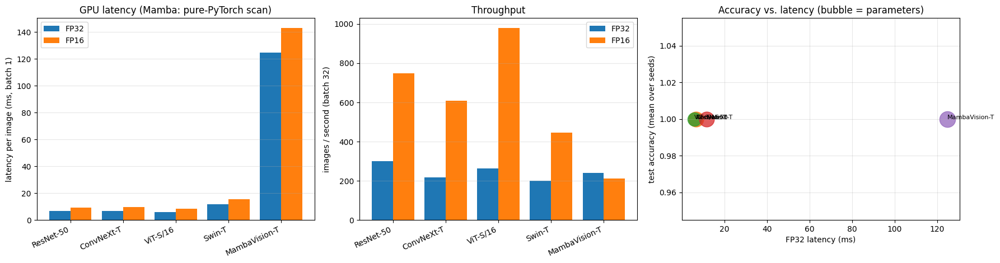

In [56]:
fig, axs = plt.subplots(1, 3, figsize=(18, 4.8)); lab = [MODELS[t]['label'] for t in EFF.index]; x = np.arange(len(lab)); cols = plt.cm.tab10.colors
axs[0].bar(x - 0.2, EFF.lat_ms_fp32, 0.4, label='FP32'); axs[0].bar(x + 0.2, EFF.lat_ms_fp16, 0.4, label='FP16'); axs[0].set_xticks(x); axs[0].set_xticklabels(lab, rotation=25, ha='right')
axs[0].set_ylabel('latency per image (ms, batch 1)'); axs[0].set_title('GPU latency (Mamba: pure-PyTorch scan)'); axs[0].legend(); axs[0].grid(axis='y', alpha=.3)
axs[1].bar(x - 0.2, EFF.throughput_ips_fp32, 0.4, label='FP32'); axs[1].bar(x + 0.2, EFF.throughput_ips_fp16, 0.4, label='FP16'); axs[1].set_xticks(x); axs[1].set_xticklabels(lab, rotation=25, ha='right')
axs[1].set_ylabel('images / second (batch 32)'); axs[1].set_title('Throughput'); axs[1].legend(); axs[1].grid(axis='y', alpha=.3)
for k, t in enumerate(EFF.index):
    axs[2].scatter(EFF.loc[t, 'lat_ms_fp32'], EFF.loc[t, 'test_acc'], s=40 + 12 * EFF.loc[t, 'params_M'], color=cols[k], alpha=.75); axs[2].annotate(MODELS[t]['label'], (EFF.loc[t, 'lat_ms_fp32'], EFF.loc[t, 'test_acc']), fontsize=8)
axs[2].set_xlabel('FP32 latency (ms)'); axs[2].set_ylabel('test accuracy (mean over seeds)'); axs[2].set_title('Accuracy vs. latency (bubble = parameters)'); axs[2].grid(alpha=.3)
plt.tight_layout(); savefig('efficiency'); plt.show()

## 7. Result visualisation and error analysis (Task 6)

### 7.1 Correct and incorrect classifications

For every model: the four test images it classifies correctly **with the highest confidence** and the four it gets wrong **with the highest confidence** (the most "surprising" mistakes). Titles show the true class, the predicted class and the predicted probability of *Dirty*. First seed.

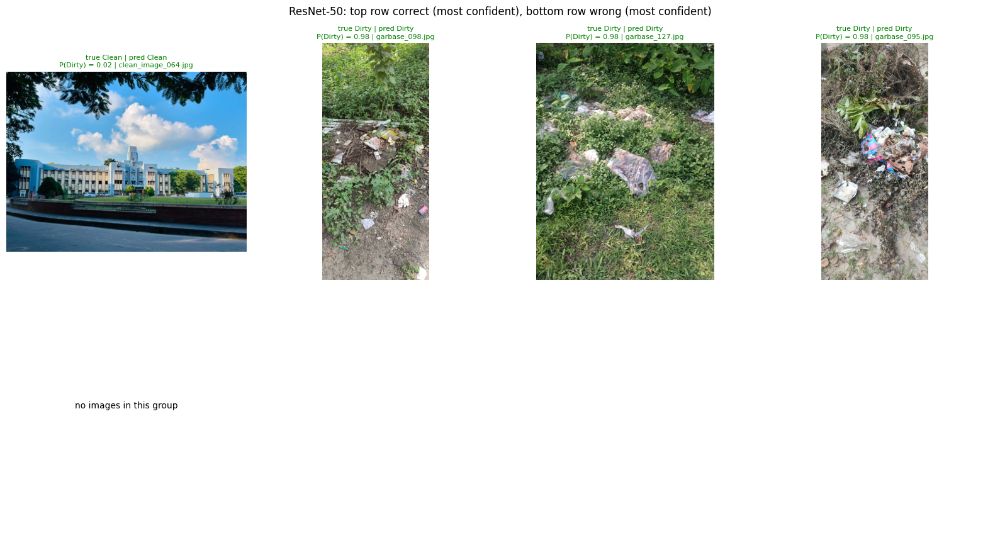

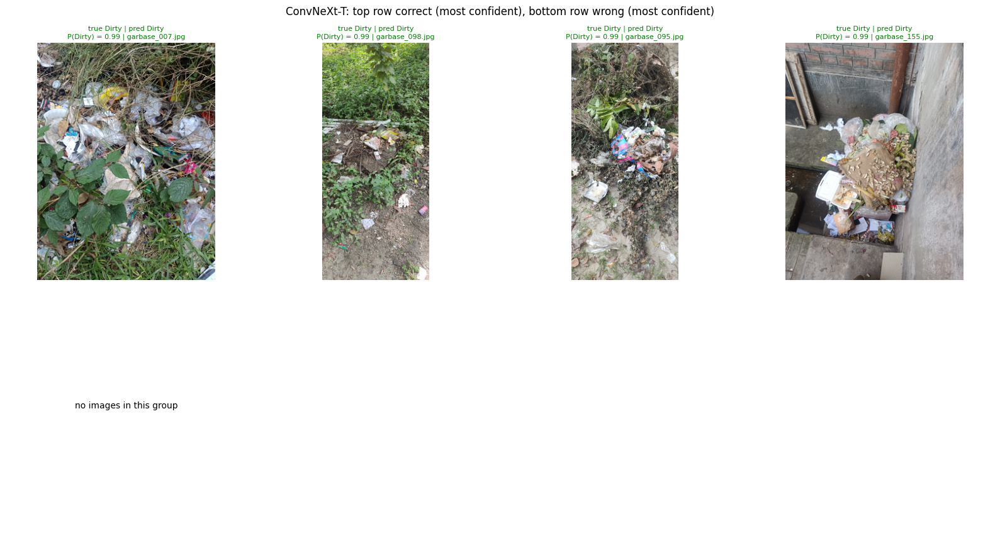

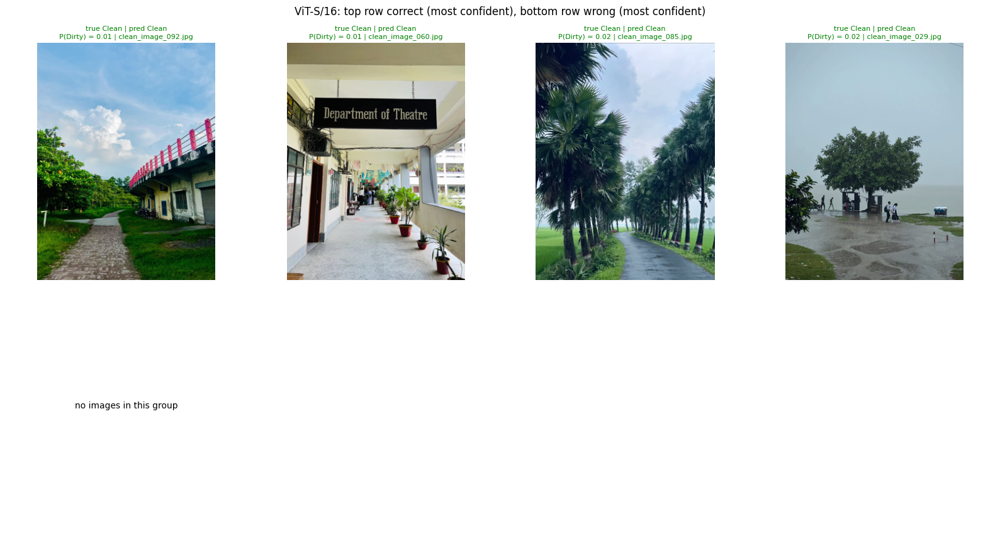

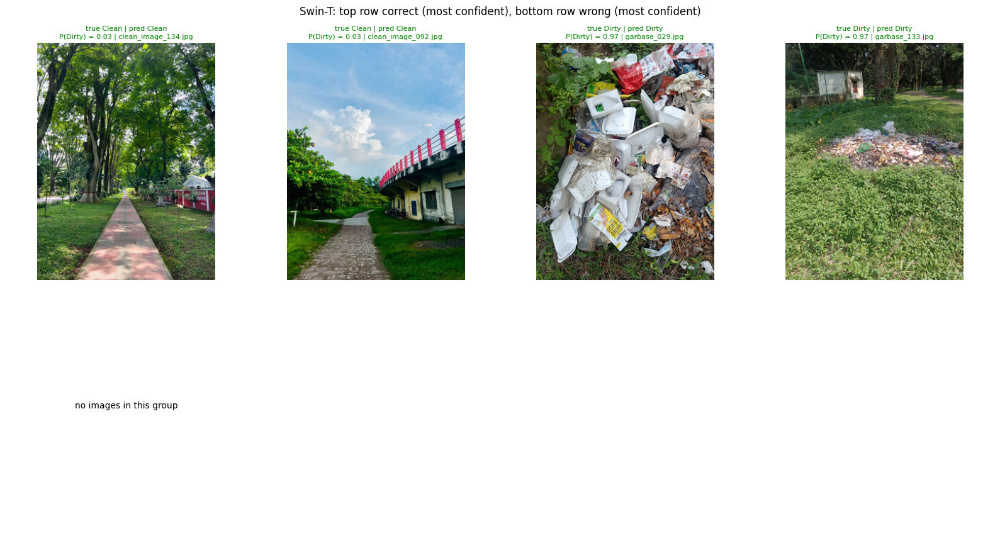

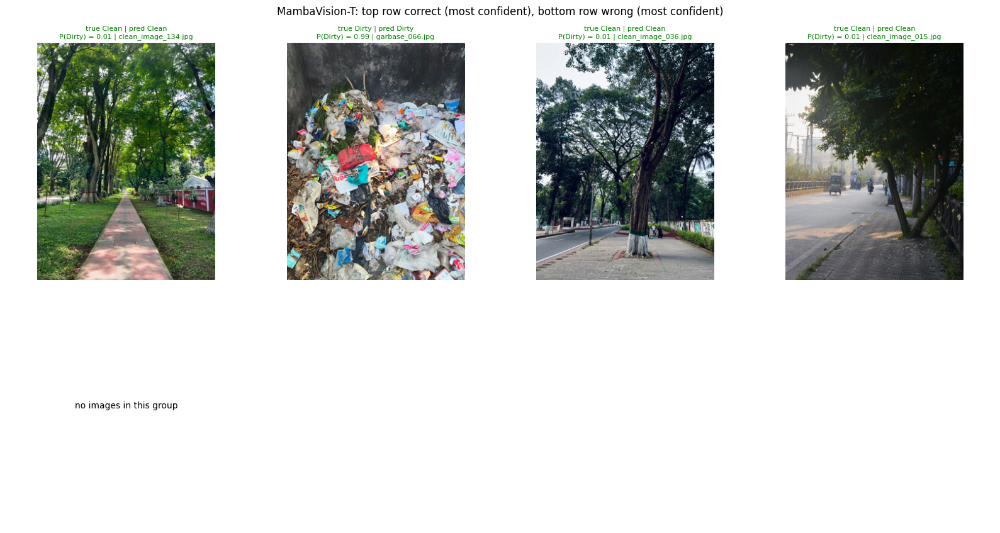

In [57]:
TEST_IMG = {i: CACHE[TEST.iloc[i].file_id] for i in range(len(TEST))}
def gallery(tag, correct, k=4):
    p = PRED[(tag, S0)]['pt']; ok = p.argmax(1) == YT; idx = np.where(ok == correct)[0]
    idx = idx[np.argsort(-p[idx].max(1))][:k]
    return idx

def draw_gallery(tag):
    p = PRED[(tag, S0)]['pt']; fig, axs = plt.subplots(2, 4, figsize=(16, 8.6))
    for row, correct in enumerate((True, False)):
        idx = gallery(tag, correct)
        for ax in axs[row]: ax.axis('off')
        for ax, i in zip(axs[row], idx):
            ax.imshow(TEST_IMG[i]); ax.set_title(f'true {CLASS_NAMES[YT[i]]} | pred {CLASS_NAMES[p[i].argmax()]}\nP(Dirty) = {p[i, 1]:.2f} | {TEST.iloc[i]["name"]}', fontsize=8,
                                                  color='green' if correct else 'red')
        if len(idx) == 0: axs[row, 0].text(0.5, 0.5, 'no images in this group', ha='center');
    plt.suptitle(f'{MODELS[tag]["label"]}: top row correct (most confident), bottom row wrong (most confident)'); plt.tight_layout(); savefig(f'examples_{tag}'); plt.show()
for t in TAGS: draw_gallery(t)

### 7.2 Which test images are hard for every model?

In [58]:
WRONG = pd.DataFrame({MODELS[t]['label']: (PRED[(t, S0)]['pt'].argmax(1) != YT).astype(int) for t in TAGS}); WRONG['n_models_wrong'] = WRONG.sum(1)
WRONG['true'] = [CLASS_NAMES[v] for v in YT]; WRONG['image'] = TEST.name.values
print('number of test images by how many models misclassify them:'); print(WRONG.n_models_wrong.value_counts().sort_index().to_string())
hard = WRONG[WRONG.n_models_wrong >= max(2, len(TAGS) // 2 + 1)].sort_values('n_models_wrong', ascending=False)
print(f'\nimages misclassified by at least {max(2, len(TAGS) // 2 + 1)} of {len(TAGS)} models:'); display(hard)
WRONG.to_csv(DIRS['tables'] / 'errors_per_image_seed0.csv')
sel = list(hard.index[:8])
if sel:
    fig, axs = plt.subplots(2, 4, figsize=(16, 8.6)); axs = axs.ravel()
    for ax in axs: ax.axis('off')
    for ax, i in zip(axs, sel):
        probs = ', '.join(f'{MODELS[t]["label"][:6]} {PRED[(t, S0)]["pt"][i, 1]:.2f}' for t in TAGS)
        ax.imshow(TEST_IMG[i]); ax.set_title(f'true {CLASS_NAMES[YT[i]]} | wrong in {int(WRONG.n_models_wrong[i])}/{len(TAGS)} models\nP(Dirty): {probs}', fontsize=7)
    plt.tight_layout(); savefig('hard_images'); plt.show()

number of test images by how many models misclassify them:
n_models_wrong
0    45

images misclassified by at least 3 of 5 models:


,ResNet-50,ConvNeXt-T,ViT-S/16,Swin-T,MambaVision-T,n_models_wrong,true,image


### 7.3 What do the models look at? (SmoothGrad saliency)

The saliency map shows how strongly each input pixel changes the score of the predicted class (gradient magnitude, averaged over 12 noisy copies of the image). It works for every architecture, but it is a **rough** explanation: it highlights sensitivity, not proof of reasoning. Rows: two images classified correctly by all models, then the hardest images of Section 7.2.

MambaVision-T weights loaded | scan: mamba_ssm CUDA kernels | missing (non-head): 0 | unexpected: 0


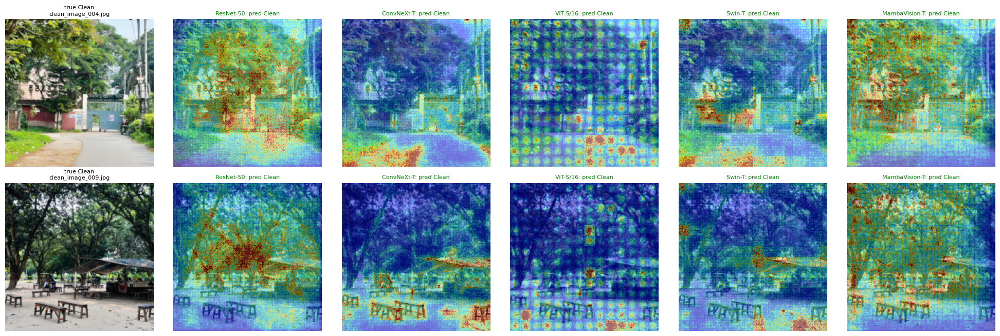

In [59]:
def saliency(model, info, img_np, n=12, sigma=0.15):
    ev = make_tfms(info['mean'], info['std'])[1]; x = ev(Image.fromarray(img_np))[None].to(DEVICE); rng = (x.max() - x.min()).item()
    model.eval(); grads = torch.zeros_like(x)
    with torch.no_grad(): cls = model(x).argmax(1).item()
    for _ in range(n):
        xn = (x + sigma * rng * torch.randn_like(x)).requires_grad_(True); out = model(xn); model.zero_grad(set_to_none=True); out[0, cls].backward(); grads += xn.grad.abs()
    g = (grads / n).amax(1)[0].cpu().numpy(); g = np.clip(g / (np.percentile(g, 99) + 1e-8), 0, 1)
    base = np.array(ev.transforms[0](Image.fromarray(img_np)).convert('RGB')); base = np.array(T.CenterCrop(IMG_SIZE)(Image.fromarray(base)))
    heat = cv2.applyColorMap((g * 255).astype(np.uint8), cv2.COLORMAP_JET)[..., ::-1]; heat = cv2.resize(heat, (base.shape[1], base.shape[0]))
    return base, (0.55 * base + 0.45 * heat).astype(np.uint8), cls

all_right = [i for i in range(len(TEST)) if WRONG.n_models_wrong[i] == 0][:2]
SAL_IDX = all_right + list(WRONG.sort_values('n_models_wrong', ascending=False).index[:2]); SAL_IDX = list(dict.fromkeys(SAL_IDX))[:4]
SAL = {}
for t in TAGS:
    try:
        model, info, _ = build_model(t); model.load_state_dict(torch.load(ckpt_path(t, S0), map_location=DEVICE))
        SAL[t] = {i: saliency(model, info, TEST_IMG[i]) for i in SAL_IDX}; del model; gc.collect(); torch.cuda.empty_cache()
    except Exception as e: print(f'saliency failed for {t}: {type(e).__name__}: {str(e)[:150]}')
if SAL:
    fig, axs = plt.subplots(len(SAL_IDX), len(SAL) + 1, figsize=(3.3 * (len(SAL) + 1), 3.3 * len(SAL_IDX)), squeeze=False)
    for r, i in enumerate(SAL_IDX):
        axs[r, 0].imshow(list(SAL.values())[0][i][0]); axs[r, 0].set_title(f'true {CLASS_NAMES[YT[i]]}\n{TEST.iloc[i]["name"]}', fontsize=8); axs[r, 0].axis('off')
        for c, t in enumerate(SAL):
            base, ov, cls = SAL[t][i]; axs[r, c + 1].imshow(ov); axs[r, c + 1].axis('off'); axs[r, c + 1].set_title(f'{MODELS[t]["label"]}: pred {CLASS_NAMES[cls]}', fontsize=8, color='green' if cls == YT[i] else 'red')
    plt.tight_layout(); savefig('saliency_maps'); plt.show()

### 7.4 Which image properties are linked to errors?

For every test image the notebook measures simple properties and relates them to the models' mistakes (first seed): mean **brightness**, **contrast** (grey-level standard deviation), **sharpness** (variance of the Laplacian; low = blurry), **colourfulness** (Hasler-Suesstrunk measure), **edge density** (share of edge pixels, a proxy for clutter), **saturation**, original **resolution**, and whether the photo is a portrait or landscape. Properties are split into three equal-sized bins; the table shows the error rate per bin (mean over models). With about 45 images, bins hold about 15 images: treat patterns as hints, not as findings.

,err_low,err_medium,err_high,spearman_rho,p_value
property,,,,,
brightness,0.0,0.0,0.0,NaN,NaN
contrast,0.0,0.0,0.0,NaN,NaN
sharpness,0.0,0.0,0.0,NaN,NaN
saturation,0.0,0.0,0.0,NaN,NaN
colourfulness,0.0,0.0,0.0,NaN,NaN
edge_density,0.0,0.0,0.0,NaN,NaN
megapixels,0.0,0.0,0.0,NaN,NaN


error rate by class (mean over models):
class
Clean    0.0
Dirty    0.0
error rate by orientation: {0.0: 0.0, 1.0: 0.0} (1 = portrait)


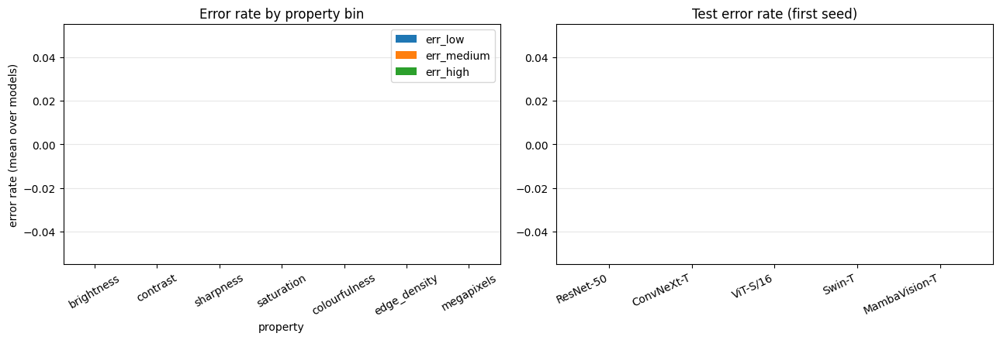

In [60]:
def descriptors(a, r):
    g = cv2.cvtColor(a, cv2.COLOR_RGB2GRAY); hsv = cv2.cvtColor(a, cv2.COLOR_RGB2HSV); R, G, B = [a[..., k].astype(float) for k in range(3)]
    rg, yb = R - G, 0.5 * (R + G) - B
    return dict(brightness=g.mean() / 255, contrast=g.std() / 255, sharpness=cv2.Laplacian(g, cv2.CV_64F).var(), saturation=hsv[..., 1].mean() / 255,
                colourfulness=math.sqrt(rg.std() ** 2 + yb.std() ** 2) + 0.3 * math.sqrt(rg.mean() ** 2 + yb.mean() ** 2),
                edge_density=(cv2.Canny(g, 100, 200) > 0).mean(), megapixels=r.W * r.H / 1e6, portrait=float(r.H > r.W))
DESC = pd.DataFrame([descriptors(TEST_IMG[i], TEST.iloc[i]) for i in range(len(TEST))])
DESC['err_rate'] = (WRONG[[MODELS[t]['label'] for t in TAGS]].mean(1)).values; DESC['n_wrong'] = WRONG.n_models_wrong.values; DESC['class'] = WRONG.true.values
rows = []
for c in [c for c in DESC.columns if c not in ('err_rate', 'n_wrong', 'class', 'portrait')]:
    bins = pd.qcut(DESC[c].rank(method='first'), 3, labels=['low', 'medium', 'high']); e = DESC.groupby(bins, observed=True).err_rate.mean()
    rho, pv = stats.spearmanr(DESC[c], DESC.err_rate)
    rows.append(dict(property=c, err_low=e.get('low', np.nan), err_medium=e.get('medium', np.nan), err_high=e.get('high', np.nan), spearman_rho=rho, p_value=pv))
FACT = pd.DataFrame(rows).set_index('property'); display(FACT.round(3)); FACT.round(4).to_csv(DIRS['tables'] / 'error_vs_image_properties.csv')
print('error rate by class (mean over models):'); print(DESC.groupby('class').err_rate.mean().round(3).to_string())
print('error rate by orientation:', DESC.groupby('portrait').err_rate.mean().round(3).to_dict(), '(1 = portrait)')
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5)); FACT[['err_low', 'err_medium', 'err_high']].plot.bar(ax=axs[0], rot=30); axs[0].set_ylabel('error rate (mean over models)'); axs[0].set_title('Error rate by property bin'); axs[0].grid(axis='y', alpha=.3)
axs[1].bar(range(len(TAGS)), [1 - corr[t].mean() for t in TAGS]); axs[1].set_xticks(range(len(TAGS))); axs[1].set_xticklabels([MODELS[t]['label'] for t in TAGS], rotation=25, ha='right'); axs[1].set_title('Test error rate (first seed)'); axs[1].grid(axis='y', alpha=.3)
plt.tight_layout(); savefig('error_factors'); plt.show()